# HW4: Stock prediction and a 90-day strategy

**Yixiao Yang — UCB MFE Python Pre-Program, Fall 2026**

The complete experiment covers **2016-04-01 through 2026-09-30**. Starting with $1 million, the strategy ends at **$1,311,729.05** and the S&P 500 total-return benchmark at **$4,402,746.78**. The report explains the underperformance and source limitations.

The original model and all **249,796 forecasts** remain unchanged. Verified corporate actions and missing observed prices repaired portfolio accounting. Both an independent full ledger reconstruction and a full feature/model/prediction regeneration passed. This notebook contains actual saved outputs and defaults to displaying them.

## 1. Open the project

Select the Python environment used for `requirements.txt`. This notebook is the main reading and execution entry point. The core implementation is in `data.py`, `hw4.py` and `backtester.py`; tests and the independent audit remain separate.

The first cell verifies and restores the supporting data ZIP. Saved results, the chart, the full explanation and the source appendix are also embedded below, so they can be read directly in this notebook.

In [1]:
from pathlib import Path
import sys

candidates = [Path.cwd(), Path.cwd() / 'Homeworks' / 'HW4' / 'Yixiao_Yang']
HERE = next((p.resolve() for p in candidates if (p / 'hw4.py').is_file()), None)
if HERE is None:
    raise FileNotFoundError('Open this notebook from Yixiao_Yang or the course repository root.')
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))
from audit_hw4 import ensure_supporting_files
ensure_supporting_files()
print('Code folder:', HERE.name)

## 2. Check accounting and information timing

The tests use hand-calculated examples and explicitly synthetic fixtures. They verify fees, fixed budgets, separate 90-day lots, missing observations, terminal valuation, cash-claim conversion and release, stock exchanges, publication dates and chronological training. Synthetic data do not supply any reported investment results.

In [2]:
import subprocess

check = subprocess.run(
    [sys.executable, '-m', 'unittest', 'discover', '-s', str(HERE), '-p', 'test_*.py', '-v'],
    cwd=HERE, text=True, capture_output=True,
)
print(check.stderr[-1000:])
check.check_returncode()

## 3. Choose whether to regenerate

`REGENERATE = False` reads the included completed results. No database is needed merely to view them. For a full regeneration, set it to `True` and supply the official `equities_top2000.duckdb`. Included source evidence is used offline for the accounting overlay. The smaller classroom file cannot reproduce the final period.

In [3]:
from hw4 import find_database

REGENERATE = False
DATABASE = find_database()
# Example alternative on Windows:
# DATABASE = Path(r'C:\Users\YourName\Downloads\equities_top2000.duckdb')

if REGENERATE and not DATABASE.is_file():
    raise FileNotFoundError('Set DATABASE to the official equities_top2000.duckdb before rerunning.')
print('Mode:', 'reproduce full-file experiment' if REGENERATE else 'read saved actual results')

## 4. Run the fixed research protocol

The model predicts next-session-entry to 90-calendar-day-exit adjusted returns using 12 causal price and financial features. Training-only clipping, imputation and scaling precede Ridge regression. Development years 2013–2015 select alpha from 10, 100 and 1000; the selected value is 1000. Final-period quarterly refits use strictly completed labels. Accounting-only source corrections never feed model fitting or stock selection.

### Feature definitions and availability

I use Ridge regression to predict the gross return of a purchase held for
90 calendar days. It gives me a simple model with one penalty to validate,
instead of a large model search. It is not assumed to beat the market.

Let `P_t` be the observed adjusted close at the signal date. Lookbacks count
market sessions, and daily returns are `P_t / P_(t-1) - 1`. Price gaps stay
missing; they are never filled before feature calculation.

| Feature | Definition |
|---|---|
| `momentum_21` | `P_t / P_(t-21) - 1` |
| `momentum_63` | `P_t / P_(t-63) - 1` |
| `momentum_252_21` | `P_(t-21) / P_(t-252) - 1`, excluding the last month |
| `volatility_63` | Sample standard deviation of 63 daily returns, multiplied by `sqrt(252)` |
| `drawdown_252` | `P_t / max(P_(t-251), ..., P_t) - 1` |
| `net_margin` | Quarterly net income / revenue |
| `operating_roa` | Quarterly operating income / total assets |
| `debt_to_assets` | Total debt / total assets |
| `cash_to_assets` | Cash and equivalents / total assets |
| `fcf_to_assets` | Quarterly free cash flow / total assets |
| `accruals_to_assets` | `(net income - operating cash flow) / total assets` |
| `filing_age_days` | Days since the report's availability date |

Only quarterly filings with filing dates after fiscal end are used. A report
becomes available at **filing date plus one calendar day**. The backward
join never uses a future report, and an older fiscal period filed late cannot
replace a newer known period. Financial ratios older than 550 days from
fiscal end become missing. Revenue/assets denominators must be positive.
The cash-flow and profitability ratios use reported quarters, not annualized
or trailing-twelve-month quantities.

For eligibility I require 63 complete trailing daily returns and membership
in the historical **entry quarter**. Longer lookbacks and financials may be
missing. All three preprocessing steps are learned on training data only:
1%/99% feature clipping, median imputation with missing-value indicators,
and standardization. I do not use current sector or active-status fields as
features or screens. I also do not require a stock to survive or have a
future exit quote before deciding to buy it.



In [4]:
import json
from hw4 import run_experiment

OUTPUT = HERE / 'outputs'
if REGENERATE:
    status = run_experiment(DATABASE, OUTPUT, batch_size=128)
else:
    status = json.loads((OUTPUT / 'RUN_STATUS.json').read_text(encoding='utf-8'))
status

{'status': 'completed',
 'complete': True,
 'stage': 'frozen-prediction accounting replay',
 'reason': None,
 'first_entry_session': '2016-04-01',
 'last_valid_session': '2026-09-30',
 'requested_end': '2026-09-30',
 'runtime_seconds': 3.77,
 'frozen_predictions_sha256': 'fdb6fc0c8a176b72b00d8125e4350f98a32c1afd77f53b96929c96f70295ac82',
 'selected_alpha': 1000.0,
 'corporate_actions': 22,
 'overlay_price_rows': 273}

## 5. Full-period performance

Both portfolios cover the same 2,640 test market sessions and start from $1 million. Maximum drawdown is a signed loss; Sharpe uses a 2% annual risk-free rate. The strategy underperformed, which is retained as the actual result.

,final_value,total_return,cagr,max_drawdown,sharpe
portfolio,,,,,
strategy,1.311729e+06,0.311729,0.026187,-0.693980,0.190265
benchmark,4.402747e+06,3.402747,0.151662,-0.337905,0.772501


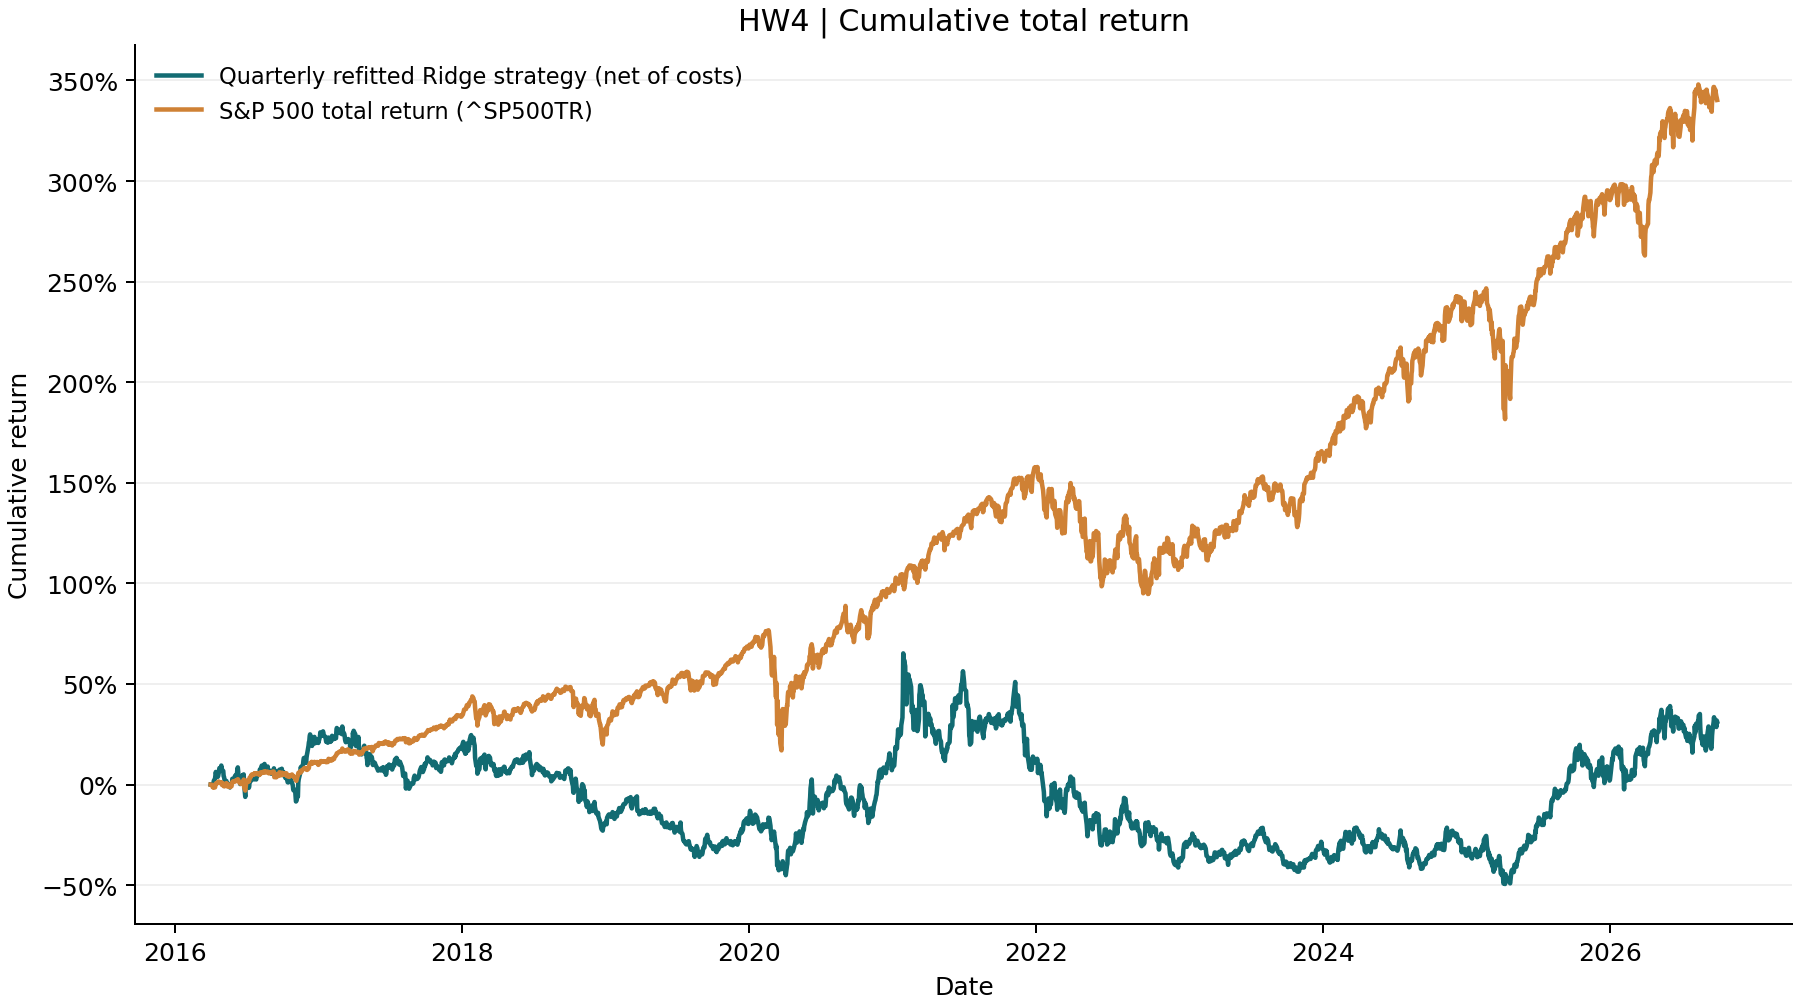

In [5]:
import pandas as pd
from IPython.display import display, Image, Markdown

status = json.loads((OUTPUT / 'RUN_STATUS.json').read_text(encoding='utf-8'))
assert status.get('complete'), 'The displayed result must cover the full requested period.'
metrics = pd.read_csv(OUTPUT / 'metrics.csv', index_col='portfolio')
display(metrics)
display(Image(filename=str(OUTPUT / 'cumulative_returns.png')))
print('Full period:', status.get('first_entry_session', '2016-04-01'), 'through',
      status.get('last_valid_session', '2026-09-30'))

## 6. Validate fit timing and independently reconciled holdings

All 42 final fits use labels ending before the fit date. The independent audit reconstructs the account from source data and the exported event ledger without importing the portfolio engine. It also validates membership, price-source lineage and the unchanged prediction fingerprint. The saved result files are checked against the audit's hashes below.

In [6]:
import hashlib

display(pd.read_csv(OUTPUT / 'validation.csv'))
fit_audit = pd.read_csv(OUTPUT / 'fit_audit.csv', parse_dates=['fit_date', 'last_training_label_end'])
assert (fit_audit.last_training_label_end < fit_audit.fit_date).all()
print('All', len(fit_audit), 'fits use strictly completed targets.')

proof = OUTPUT / 'FULL_ACCOUNTING_AUDIT.json'
if proof.is_file():
    audit = json.loads(proof.read_text(encoding='utf-8'))
    assert audit['audit_passed'] and audit['complete_final_period_verified']
    for filename, digest in audit['export_sha256'].items():
        assert hashlib.sha256((OUTPUT / filename).read_bytes()).hexdigest() == digest, filename
    print('Independent full audit passed; all exported evidence hashes match.')
    print('Final cash:', audit['terminal_cash'])
    print('Final stock value:', audit['terminal_stock_value'])
    print('Final NAV:', audit['terminal_nav'])
    print('Verified accounting price continuations:', 273)
else:
    print('Full regeneration is complete. To regenerate the independent frozen-forecast audit,')
    print('run the README quick-replay commands: hw4.py --replay, then audit_hw4.py.')

positions = pd.read_csv(OUTPUT / 'open_positions.csv')
print('Terminal open lots:', len(positions))
display(positions[['symbol', 'entry_date', 'maturity_date', 'market_value', 'stale_sessions']].head(10))

,validation_year,fit_date,training_rows,last_training_label_end,eligible_validation_rows,evaluated_validation_rows,unevaluated_validation_rows,last_validation_label_end,model,alpha,rmse,mean_monthly_rank_ic
0,2013,2012-12-31,63943,2012-12-03,23808,23802,6,2014-03-03,training_mean,NaN,2.535546,NaN
1,2013,2012-12-31,63943,2012-12-03,23808,23802,6,2014-03-03,ridge,10.0,13.835372,0.019693
2,2013,2012-12-31,63943,2012-12-03,23808,23802,6,2014-03-03,ridge,100.0,13.807770,0.019630
3,2013,2012-12-31,63943,2012-12-03,23808,23802,6,2014-03-03,ridge,1000.0,13.542328,0.019239
4,2014,2013-12-31,89706,2013-12-30,23843,23841,2,2015-03-02,training_mean,NaN,1.856016,NaN
5,2014,2013-12-31,89706,2013-12-30,23843,23841,2,2015-03-02,ridge,10.0,9.578861,-0.043090
6,2014,2013-12-31,89706,2013-12-30,23843,23841,2,2015-03-02,ridge,100.0,9.566187,-0.043134
7,2014,2013-12-31,89706,2013-12-30,23843,23841,2,2015-03-02,ridge,1000.0,9.442899,-0.043601
8,2015,2014-12-31,113539,2014-12-30,23884,19895,3989,2015-12-30,training_mean,NaN,1.502368,NaN
9,2015,2014-12-31,113539,2014-12-30,23884,19895,3989,2015-12-30,ridge,10.0,7.955131,-0.073887


,symbol,entry_date,maturity_date,market_value,stale_sessions
0,AAOI,2026-08-03,2026-11-01,18229.280001,0
1,TE,2026-08-03,2026-11-01,15815.269722,0
2,AXTI,2026-08-03,2026-11-01,22816.355100,0
3,MXL,2026-08-03,2026-11-01,27237.349948,0
4,SNDK,2026-08-03,2026-11-01,27340.853058,0
5,BE,2026-08-03,2026-11-01,25678.587776,0
6,MOVE,2026-08-03,2026-11-01,22102.522560,0
7,VICR,2026-08-03,2026-11-01,27387.014683,0
8,BRUN,2026-08-03,2026-11-01,15790.279585,0
9,WLFC,2026-08-03,2026-11-01,13906.824743,0


## 7. Findings, limitations and future work

The report contains the full strategy/benchmark comparison, the unsuccessful validation result, the severe original target anomalies and the accounting conventions. `outputs/CORPORATE_ACTIONS.md` supplies dates, consideration and primary-source links; `verification/market_data_sources/` holds the supplemental quotation evidence. The initial failure summary and original model-validation evidence remain in the supporting evidence ZIP.

In [7]:
report = (OUTPUT / 'REPORT.md').read_text(encoding='utf-8')
report = report.replace(
    '![Strategy and benchmark cumulative returns](cumulative_returns.png)',
    'The cumulative-return chart is displayed in section 5 above.',
)
report = report.replace(
    '[CORPORATE_ACTIONS.md](CORPORATE_ACTIONS.md)',
    'the corporate-action source appendix at the end of this notebook',
)
display(Markdown(report))

# HW4 findings — Yixiao Yang

## 1. Completed experiment and result

The recorded portfolio now covers **April 1, 2016 through September 30, 2026**,
all **2,640 market sessions**, with the original $1,000,000 principal.
The full course database was verified against its published SHA-256 before use.
The strategy **underperformed** the S&P 500 total-return benchmark by
**$3,091,017.72** of final value. The signed cumulative-return difference is
**-309.10 percentage points**, and the
signed CAGR difference is **-12.55 percentage points**.
These are simulated results under the stated data and execution assumptions.

| Metric | Strategy, net of modeled costs | S&P 500 total return |
| --- | --- | --- |
| Final portfolio value | $1,311,729.05 | $4,402,746.78 |
| Cumulative return | 31.17% | 340.27% |
| CAGR | 2.62% | 15.17% |
| Maximum drawdown (signed) | -69.40% | -33.79% |
| Daily-return Sharpe; 2% annual risk-free | 0.1903 | 0.7725 |

The cumulative-return chart is displayed in section 5 above.

The original unaugmented run stopped at BID in October 2019. Its failure
summary and original fit/validation evidence are retained in the supporting
evidence ZIP under `verification/original_incomplete_attempt/`. I investigated
the security identity and mandatory consideration, then completed accounting
with source-verified corporate actions and missing historical observations.
**The 249,796 forecasts, alpha, features, ranking and allocation rules were
not retuned.** Original prediction SHA-256: `fdb6fc0c8a176b72b00d8125e4350f98a32c1afd77f53b96929c96f70295ac82`.
This is a repaired accounting evaluation of the same frozen experiment,
not a claim that the final period remained unseen during the investigation.

## 2. Model, features and information timing

Ridge regression predicts the gross adjusted-price return from the next
session's entry close to the first market session on or after entry plus
90 calendar days. Ridge was chosen as a transparent numeric baseline with
one regularization parameter; strong performance was not assumed.

The 12 inputs are 21- and 63-session momentum; 252-session momentum excluding
the latest 21 sessions; annualized 63-session return volatility; drawdown
from the 252-session high; quarterly net margin, operating income/assets,
debt/assets, cash/assets, free cash flow/assets, accruals/assets; and filing
age in days. Exact formulas are in `../HW4.ipynb` and `../data.py`.

Price features use only the signal close and earlier observations. They
are calculated without filling gaps. Quarterly financial reports become
available at filing date plus one calendar day. Backward joins exclude
future reports, reject filing dates on/before fiscal period end, and prevent
a late filing of an older fiscal period from displacing a newer known one.
Financial ratios become missing after 550 days from fiscal end.

Every fit learns feature clipping at its training 1st/99th percentiles,
median imputation with missing indicators, and standardization only on its
training sample. This clips input features, **not the target return**.
Current sector and active-status snapshots are not model inputs or screens.

Eligibility requires historical entry-quarter membership and 63 complete
trailing daily returns. Inactive securities remain in the union. A missing
future exit quote does not remove a prediction candidate. Once purchased,
a lot remains held if the issuer leaves subsequent quarterly universes.

## 3. Development validation and the unsuccessful modeling result

Development entries are January 2010–December 2015. Annual chronological
validation folds use entry years 2013, 2014 and 2015. A fit includes only
signals before its date and targets whose exact 90-day exit is strictly
earlier than the fit. Validation used outcomes ending by December 31, 2015.
The January–March 2016 buffer permits earlier targets to finish, with no
sampled entry dates in that buffer. The final-period rule makes quarterly
expanding-window refits using newly completed outcomes, holding the design
and chosen alpha fixed. All 42 final fit dates are exported.

The prespecified rule minimizes the equally weighted mean annual RMSE among
alpha 10, 100 and 1000; ties favor the smaller alpha. It selected **1000**.

| Model | Mean annual validation RMSE (decimal return) |
| --- | --- |
| Ridge, alpha=10 | 10.456455 |
| Ridge, alpha=100 | 10.440347 |
| Ridge, alpha=1000 | 10.284590 |
| Training-mean prediction | 1.964643 |

| Validation year | Evaluated labels | RMSE | Mean monthly rank IC |
| --- | --- | --- | --- |
| 2013 | 23,802 | 13.542328 | 0.019239 |
| 2014 | 23,841 | 9.442899 | -0.043601 |
| 2015 | 19,895 | 7.868542 | -0.075035 |

The selected Ridge performs worse than the training-mean reference in
development RMSE, with negative mean rank IC in two validation years.
This is an unsuccessful baseline, not evidence of a reliable predictive edge.
The reference model was a diagnostic, not an unrecorded portfolio-selection
alternative. I preserved the originally specified Ridge experiment rather
than switching models after viewing the final path.

Independent SQL diagnosis found **137,420**
eligible labels completed by the development cutoff. Of these, 17 exceed a
decimal return of 10, five exceed 100, and two exceed 1,000. The most extreme
AAM observation uses an entry adjusted price of 0.1915 and an exit value of
20,461.50, implying a decimal return of about 106,847.56. These positive finite
numbers pass a basic numeric check but are not verified economic returns.
The largest training target accounts for about 79.4% of centered squared
deviations in the 2013 fold; the largest ten account for about 99.997%.
Feature clipping cannot fix such target contamination. The training-mean
baseline also inherits the contaminated mean. See `data_issues.json` and
`extreme_development_labels.csv` for the original evidence.

## 4. Portfolio construction and accounting

At the last close before each month's first market session, eligible names
are ranked by predicted return, then ticker for ties. Up to 20 fixed orders
are scheduled for the next session's close. A cohort's inclusive budget is
`min(previous-close available cash, previous-close NAV / 3)`, with one
twentieth assigned to each selected slot. Fewer candidates leave cash unused.
Same-day maturity receipts cannot increase orders already decided yesterday.

The account uses fractional adjusted-price units, long-only holdings, no
borrowing and no leverage. A buy with inclusive budget B at adjusted price P
receives `B / (P × 1.001)` units. Ordinary sales return `units × P × 0.999`.
Cash earns 0%. Each lot has its own 90-calendar-day maturity; a market closure
rolls the exit to the next session. Repeated monthly positions in one issuer
can overlap, so there is no aggregate issuer-weight cap.

Dividends are not separately added to adjusted-price returns. At the test
end, still-open lots are marked rather than forcibly sold. Their later
maturities and prices after September 30, 2026 are not used.

| Accounting event | Recorded lot events |
| --- | --- |
| BUY | 2459 |
| SELL | 2401 |
| CASH_MERGER_CONVERSION | 18 |
| CASH_CLAIM_RELEASE | 18 |
| SECURITY_CONVERSION | 2 |

Final available cash is **$423,045.31**, stocks are
**$888,683.74**, and cash claims are
**$0.00**, totaling **$1,311,729.05**.
There are **40** open lots, with
**0** stale final marks.
Total modeled costs are **$62,168.58**. Average available cash
as a fraction of daily NAV is **21.57%**.
`trades.csv`, `orders.csv`, `open_positions.csv` and `daily_nav.csv` provide
the corresponding accounting trail.

## 5. Corporate actions and missing observations

The original strict rule still cancels a missing-entry order without reranking,
carries an ordinary missing mark for at most five sessions, and stops at a
missing maturity quote or a sixth stale session. The completed path did not
require disabling those checks. Instead, sourced observations or legally
verified consideration resolve the relevant data gaps.

The separate evidence registry covers **22** events or
identity continuations: ALPN, ASGN, BID, BSGM, BVH, CCXI, CIFRW, DISH, ECOL, FI, GPS, HOUS, IMGN, MAXR, MFH, NCR, PEGY, RCB, RETA, RXDX, SOFIW, TA. Full dates, amounts, unit formulas
and primary-source links appear in the corporate-action source appendix at the end of this notebook
and `../corporate_actions.json`.

For a mandatory cash merger or redemption, the stock/instrument converts to
a fixed cash claim on the effective daily accounting date. The conversion
does not create a fictitious exchange sale. The claim counts in NAV but is
ring-fenced from new purchases until the lot's original maturity, when one
modeled exit charge is applied. This explicitly preserves the original
capital-allocation horizon. Actual broker payment timing and investor-specific
taxes are not observable or modeled. For mandatory stock mergers, units convert
to the sourced successor ratio while cost and original maturity remain intact.

Some original eligible names are warrants or baby bonds despite being in
the course's stock universe. The frozen no-exercise strategy receives the
mandatory default cash redemption for SOFIW and CIFRW; the optional, more
valuable cashless exercise is not retroactively chosen. RCB is a 6.2% note,
so its mandatory redemption includes the contractually accrued interest;
the evidence appendix shows that calculation. These instrument-classification
problems are substantive limitations of the original selection experiment.

Pure renames use observed successor quotes, with an explicit adjustment-basis
bridge where necessary. The NCR lot entered after the earlier NCR/NATL split,
so it receives no historical spinoff distribution. Historical WOLF prices are
required for its 2024 holding; its 2025 reorganization cannot supply those
earlier values. Likewise, Sotheby's 2019 BID holding is not connected to a
different issuer later reusing BID. No missing position is silently deleted,
assigned its last quote as a cash payoff, or written to zero without evidence.

These repairs only enter portfolio accounting. Features and training targets
still use the original course observations. Consequently, future legal-identity
research or a currently retrieved price cannot improve earlier model inputs.
The original dataset's remaining positive-but-economically-wrong prices are
not all independently certified merely because the ledger now reconciles.

## 6. Benchmark, metrics and risk

The comparator buys $1,000,000 of `^SP500TR` at the April 1, 2016 close and
holds through September 30, 2026. Both paths have a prior-session $1,000,000
anchor, so the strategy's initial transaction costs are included. CAGR uses
elapsed calendar days between the first and final test closes divided by
365.25. Maximum drawdown uses running portfolio highs and is reported as a
negative percentage. Sharpe uses arithmetic daily excess returns over
`1.02**(1/252) - 1`, sample daily standard deviation, and `sqrt(252)`.

Annual compounded returns, including the two partial calendar years, are:

| Year | Strategy | Benchmark |
| --- | --- | --- |
| 2016 (partial) | 20.68% | 9.78% |
| 2017 | -2.23% | 21.83% |
| 2018 | -31.62% | -4.38% |
| 2019 | 1.68% | 31.49% |
| 2020 | 32.45% | 18.40% |
| 2021 | 2.47% | 28.71% |
| 2022 | -43.45% | -18.11% |
| 2023 | 8.51% | 26.29% |
| 2024 | -5.43% | 25.02% |
| 2025 | 58.36% | 17.88% |
| 2026 (partial) | 28.19% | 12.75% |

This is an unhedged stock/instrument-selection strategy. It takes concentrated
exposure through repeated cohorts, pays trading costs and leaves material
cash uninvested. Its price and financial signals do not constrain issuer
quality, liquidity, market beta or aggregate security weight. Corporate-action
losses, extreme source labels and changing exposure all affect the outcome;
the comparison is not risk-matched to a permanently invested large-cap index.

The five largest individual realized lot losses illustrate what actually
happened; they are not a post-test screening list:

| Original security | Entry | Exit/release | Net realized P&L |
| --- | --- | --- | --- |
| SOFIW | 2021-12-01 | 2022-03-01 | $-20,676.40 |
| CIFRW | 2025-11-03 | 2026-02-02 | $-18,916.40 |
| INPX | 2017-04-03 | 2017-07-03 | $-16,421.43 |
| CIFRW | 2025-12-01 | 2026-03-02 | $-16,345.33 |
| INPX | 2017-06-01 | 2017-08-30 | $-15,691.58 |

## 7. Verification and reproducibility

Hand-calculated tests cover fees, cash conservation, overlapping lots,
weekend maturity, fixed budgets, stale and missing quotes, terminal value,
claim conversion/release and stock exchanges. Information-timing tests cover
filing availability, historical membership, target purging and invariance
of earlier features/predictions to changed future inputs. Synthetic fixtures
are used only for checks, not for reported investment results.

The independent reconstruction is included in `FULL_ACCOUNTING_AUDIT.json`. It reads the original database, evidence overlay and event ledger without importing the backtester, then recomputes cash, holdings, NAV, maturity dates, prior-close order budgets and risk metrics.

The original official database checksum is `a028641d96c12e6f29d5dd34e3a6ebc059074dd38351648bf0d970b1dd4095b9`.
`run_config.json` records the original protocol and the separate evidence
fingerprint. `../verification/FROZEN_STRATEGY.json` and the compressed forecast
file permit an exact replay of the same decisions. `python hw4.py --replay
--database PATH --output outputs` replays the supplied forecasts. `python
hw4.py --database PATH` regenerates features, development validation,
quarterly predictions and the same source-reconciled accounting. Minor
floating-point prediction differences across numerical-library versions
are possible; the supplied frozen replay is byte-verifiable.

## 8. Main limitations and next experiment

The course data contain 3,849 securities,
including 1,355 currently inactive
names retained for historical use. Quarterly membership is reconstructed,
not a certified point-in-time feed. Vendor financials may be restated;
filing-date joins cannot undo that. Some security types, issuer identities
and share/split bases are inconsistent, and missing outcomes can bias the
available training-label sample. Overlapping 90-day outcomes are dependent.

Accounting completion does not establish that this is a deployable strategy.
The fixed Ridge model has a clearly weak validation record, severe label
contamination and no demonstrated edge over the benchmark. A next experiment
should first establish stable security IDs and instrument types, verify
split-adjusted targets, and compare robust target treatment, a price-only
baseline and the financial model using development data alone. Liquidity,
issuer caps, costs and cash rules should also be set there. Any changes after
this review require a separately declared experiment and genuinely new
evaluation data; they should not be advertised as a newly untouched test
of the same 2016–2026 period.

## 9. Sources and AI-assisted work

- [HW4 assignment](https://github.com/yang-guo/UCB-MFE-python-preprogram-2026-winter/blob/5212932d7d2e9de49785ee2c7e0395579b42d694/Lectures/Lecture%208/hw4.md).
- [Course data guide](https://github.com/yang-guo/UCB-MFE-python-preprogram-2026-winter/blob/5212932d7d2e9de49785ee2c7e0395579b42d694/Lectures/modeling/README.md).
- [Adapted data/preprocessing conventions](https://github.com/yang-guo/UCB-MFE-python-preprogram-2026-winter/blob/5212932d7d2e9de49785ee2c7e0395579b42d694/Lectures/modeling/course_data.py).
- Corporate-action and supplemental-price sources are linked in the evidence
  appendix and stored alongside their inputs. The database itself is unmodified.

The backtester is a separate implementation for this homework. ChatGPT
assisted with code, source investigation, tests, accounting reconciliation,
documentation and report generation. Numerical statements are calculated
from the supplied data and explicit evidence overlay; they are not invented
example outputs. This package prepares the assignment for review and does
not itself publish a GitHub pull request.


## 8. Corporate-action and price-source appendix

The dates, cash entitlements, share-conversion ratios and primary-source links below document the accounting repairs. These sources did not change model features, training targets or rankings.

In [8]:
display(Markdown((OUTPUT / 'CORPORATE_ACTIONS.md').read_text(encoding='utf-8')))

# Corporate actions and security continuity

This appendix identifies the economic holdings behind legacy research tickers. These inputs repair portfolio accounting only. They do not change model features, labels, predictions, historical membership, or the selected names.

Mandatory cash consideration becomes a non-spendable cash claim on the event's accounting date. It remains at fixed value until the original 90-calendar-day maturity, then releases with the strategy's one modeled 10-basis-point exit charge. Actual broker-credit delays are not observed. The fee is a simulation convention, not a claim about issuer commissions. Mandatory share conversions preserve the original maturity and cost basis. Fractional adjusted-price units are allowed throughout.

The cash basis formula is `cash_per_raw_share × old_adj_close / old_close`. For a share exchange, the new adjusted-unit ratio is `raw_exchange_ratio × (old_adj/old_close) / (new_adj/new_close)`. A pure ticker alias with equal raw closes can be continued in the old adjusted-price unit using `old_adj / successor_adj` at a verified overlap. No separate dividend is credited when the adjusted-price series already includes it.

## BID — Sotheby's

| Field | Value |
| --- | --- |
| Action ID | BID_2019-10-03_CASH_MERGER |
| Kind | cash_merger |
| Effective/accounting date | 2019-10-03 |
| Cash per actual share/instrument | 57 |
| Cash per adjusted-price unit | 57 |
| Price-basis reference date | 2019-10-02 |
| Reference old raw close | 56.99 |
| Reference old adjusted close | 56.99 |

Ordinary outstanding Sotheby's common shares converted into the right to receive USD 57.00 in cash without interest at the merger effective time. Affiliate-owned shares and perfected appraisal claims are outside this simulated public-investor position.

Only open historical Sotheby's lots entered before 2019-10-03. Do not apply to any later security reusing BID.

Recognize the fixed cash entitlement on October 3, but keep it unavailable for new buys through each lot's original 90-day maturity. Sources establish the legal entitlement; the maturity lock and modeled exit fee are explicit simulation conventions, not actual merger settlement terms.

The supplied snapshot labels BID as Tribeca Strategic Acquisition Corp. and contains later 2026 prices for the reused ticker. Those snapshot fields and later prices do not identify the 2019 Sotheby's holding.

- [Sotheby's public merger announcement, SEC Exhibit 99.2](https://www.sec.gov/Archives/edgar/data/823094/000119312519174301/d766624dex992.htm): Publicly announced USD 57.00-per-share cash merger terms, subject to conditions.
- [Sotheby's closing Form 8-K, Introductory Note and Item 2.01](https://www.sec.gov/Archives/edgar/data/823094/000082309419000038/a8-kclosingxbrl.htm): Completed merger on October 3 and conversion of ordinary common shares to a USD 57.00 cash entitlement.
- [NYSE notice of removal from listing and registration](https://www.sec.gov/Archives/edgar/data/823094/000087666119001019/ruleprovisionnotice.htm): Merger effective before October 3 opening; shares exchanged for USD 57.00 cash; trading suspended October 3. Formal listing removal on October 14 is distinct from the merger date.

## SOFIW — SoFi Technologies, Inc.

| Field | Value |
| --- | --- |
| Action ID | SOFIW_2021-12-07_UNEXERCISED_WARRANT_REDEMPTION |
| Kind | unexercised_warrant_cash_redemption |
| Effective/accounting date | 2021-12-07 |
| Cash per actual share/instrument | 0.1 |
| Cash per adjusted-price unit | 0.1 |
| Price-basis reference date | 2021-12-06 |
| Reference old raw close | 5.5 |
| Reference old adjusted close | 5.5 |

Public warrants remaining unexercised at 5 p.m. New York on December 6, 2021 become void and entitle holders only to USD 0.10 per warrant.

Open SoFi public-warrant lots entered before the redemption deadline. This event does not apply to SOFI common stock or surviving Series H warrants.

Recognize the default redemption claim on the next market session, December 7, and retain it through the lot's original 90-day maturity before cash release and the single modeled exit fee.

- [SoFi notice of redemption of all outstanding public and private warrants](https://www.sec.gov/Archives/edgar/data/1818874/000181887421000072/exhibit992.htm): December 6 at 5 p.m. New York redemption deadline and USD 0.10 mandatory cash amount for unexercised public warrants.
- [SoFi redemption fair-market-value notice](https://www.sec.gov/Archives/edgar/data/1818874/000181887421000109/ex992.htm): Optional cashless exercise ratio of 0.361 common shares per warrant; unexercised warrants receive only USD 0.10.
- [SoFi announcement of completed warrant redemption](https://www.sec.gov/Archives/edgar/data/1818874/000181887421000118/exhibit991form8-k12152021.htm): Confirms redemption completed and public-warrant trading halt announced after the December 6 market close; Series H warrants were unaffected.

## ECOL — US Ecology, Inc.

| Field | Value |
| --- | --- |
| Action ID | ECOL_2022-05-02_CASH_MERGER |
| Kind | cash_merger |
| Effective/accounting date | 2022-05-02 |
| Cash per actual share/instrument | 48 |
| Cash per adjusted-price unit | 48 |
| Price-basis reference date | 2022-04-29 |
| Reference old raw close | 47.99 |
| Reference old adjusted close | 47.99 |

Only open US Ecology, Inc. common-stock lots acquired before 2022-05-02; no application to a different issuer reusing the symbol.

Recognize fixed cash entitlement on the event date; keep it unavailable to new buys until each lot's original 90-calendar-day maturity and then release with the single modeled 10-basis-point exit fee. These timing/cost conventions are simulated, not asserted actual broker settlement terms.

- [Republic Services closing announcement](https://investor.republicservices.com/news-releases/news-release-details/republic-services-completes-acquisition-us-ecology): Completed acquisition on May 2, 2022 for USD 48 cash per outstanding US Ecology share.
- [Republic Services merger announcement filed with the SEC](https://investor.republicservices.com/node/24451/html): Publicly announced USD 48 cash-per-share agreement.

## CCXI — ChemoCentryx, Inc.

| Field | Value |
| --- | --- |
| Action ID | CCXI_2022-10-20_CASH_MERGER |
| Kind | cash_merger |
| Effective/accounting date | 2022-10-20 |
| Cash per actual share/instrument | 52 |
| Cash per adjusted-price unit | 52 |
| Price-basis reference date | 2022-10-19 |
| Reference old raw close | 51.99 |
| Reference old adjusted close | 51.99 |

Only open ChemoCentryx, Inc. common-stock lots acquired before 2022-10-20; no application to a different issuer reusing the symbol.

Recognize fixed cash entitlement on the event date; keep it unavailable to new buys until each lot's original 90-calendar-day maturity and then release with the single modeled 10-basis-point exit fee. These timing/cost conventions are simulated, not asserted actual broker settlement terms.

- [Nasdaq corporate-action alert ECA2022-292](https://nasdaqtrader.com/TraderNews.aspx?id=eca2022-292): Merger closed before market open October 20; last trading October 19; USD 52 cash for each share. Suspension effective October 21 is not the cash-entitlement date.
- [Amgen closing announcement](https://www-ext.amgen.com/newsroom/press-releases/2022/10/amgen-successfully-completes-acquisition-of-chemocentryx): Completed acquisition for USD 52 per share in cash.
- [Amgen acquisition announcement](https://www.amgen.com/newsroom/press-releases/2022/08/amgen-to-acquire-chemocentryx-for-%244-billion-in-cash): Publicly announced USD 52-per-share cash acquisition.

## MAXR — Maxar Technologies Inc.

| Field | Value |
| --- | --- |
| Action ID | MAXR_2023-05-03_CASH_MERGER |
| Kind | cash_merger |
| Effective/accounting date | 2023-05-03 |
| Cash per actual share/instrument | 53 |
| Cash per adjusted-price unit | 53 |
| Price-basis reference date | 2023-05-02 |
| Reference old raw close | 52.99 |
| Reference old adjusted close | 52.99 |

Only open Maxar Technologies Inc. common-stock lots acquired before 2023-05-03; no application to a different issuer reusing the symbol.

Recognize fixed cash entitlement on the event date; keep it unavailable to new buys until each lot's original 90-calendar-day maturity and then release with the single modeled 10-basis-point exit fee. These timing/cost conventions are simulated, not asserted actual broker settlement terms.

- [Maxar closing Form 8-K](https://www.sec.gov/Archives/edgar/data/1121142/000110465923055309/tm2314357d3_8k.htm): Merger completed May 3; ordinary common shares automatically converted to USD 53 cash entitlement; requested removal before May 3 opening.
- [Maxar acquisition announcement, SEC Exhibit 99.1](https://www.sec.gov/Archives/edgar/data/1121142/000110465922127558/tm2232717d2_ex99-1.htm): Publicly announced USD 53-per-share cash terms.

## TA — TravelCenters of America Inc.

| Field | Value |
| --- | --- |
| Action ID | TA_2023-05-15_CASH_MERGER |
| Kind | cash_merger |
| Effective/accounting date | 2023-05-15 |
| Cash per actual share/instrument | 86 |
| Cash per adjusted-price unit | 86 |
| Price-basis reference date | 2023-05-12 |
| Reference old raw close | 86 |
| Reference old adjusted close | 86 |

Only open TravelCenters of America Inc. common-stock lots acquired before 2023-05-15; no application to a different issuer reusing the symbol.

Recognize fixed cash entitlement on the event date; keep it unavailable to new buys until each lot's original 90-calendar-day maturity and then release with the single modeled 10-basis-point exit fee. These timing/cost conventions are simulated, not asserted actual broker settlement terms.

- [TravelCenters closing Form 8-K, Items 2.01 and 3.01](https://www.sec.gov/Archives/edgar/data/1378453/000110465923060301/tm2315684d1_8k.htm): Shares converted into USD 86 cash entitlement; trading ceased before market open May 15.
- [BP announcement presentation](https://www.bp.com/content/dam/bp/business-sites/en/global/corporate/pdfs/investors/bp-travelcenters-of-america-announcement-slides-and-script.pdf): Public agreement and USD 86-per-share cash consideration.

## RXDX — Prometheus Biosciences, Inc.

| Field | Value |
| --- | --- |
| Action ID | RXDX_2023-06-16_CASH_MERGER |
| Kind | cash_merger |
| Effective/accounting date | 2023-06-16 |
| Cash per actual share/instrument | 200 |
| Cash per adjusted-price unit | 199.99999799919968 |
| Price-basis reference date | 2023-06-15 |
| Reference old raw close | 199.92 |
| Reference old adjusted close | 199.919998 |

Only open Prometheus Biosciences, Inc. common-stock lots acquired before 2023-06-16; no application to a different issuer reusing the symbol.

Recognize fixed cash entitlement on the event date; keep it unavailable to new buys until each lot's original 90-calendar-day maturity and then release with the single modeled 10-basis-point exit fee. These timing/cost conventions are simulated, not asserted actual broker settlement terms.

- [Merck closing announcement](https://www.merck.com/news/merck-completes-acquisition-of-prometheus-biosciences-inc/): Completion on June 16; all outstanding Prometheus shares acquired for USD 200 cash per share. Release timestamp is 4:04 p.m. EDT; this is end-of-day entitlement accounting, not a market execution.
- [Merck acquisition announcement](https://www.merck.com/news/merck-strengthens-immunology-pipeline-with-acquisition-of-prometheus-biosciences-inc/): Publicly announced USD 200-per-share cash terms.

## RETA — Reata Pharmaceuticals, Inc.

| Field | Value |
| --- | --- |
| Action ID | RETA_2023-09-26_CASH_MERGER |
| Kind | cash_merger |
| Effective/accounting date | 2023-09-26 |
| Cash per actual share/instrument | 172.5 |
| Cash per adjusted-price unit | 172.5 |
| Price-basis reference date | 2023-09-25 |
| Reference old raw close | 172.36 |
| Reference old adjusted close | 172.36 |

Only open Reata Pharmaceuticals, Inc. common-stock lots acquired before 2023-09-26; no application to a different issuer reusing the symbol.

Recognize fixed cash entitlement on the event date; keep it unavailable to new buys until each lot's original 90-calendar-day maturity and then release with the single modeled 10-basis-point exit fee. These timing/cost conventions are simulated, not asserted actual broker settlement terms.

- [Reata closing Form 8-K](https://www.sec.gov/Archives/edgar/data/1358762/000119312523242619/d516210d8k.htm): Merger completed September 26 and ordinary Class A and Class B shares converted into USD 172.50 cash entitlement.
- [Biogen and Reata acquisition announcement](https://investors.biogen.com/news-releases/news-release-details/biogen-acquire-reata-pharmaceuticals): Publicly announced USD 172.50 cash-per-share agreement.
- [Nasdaq Equity Corporate Actions Alert 2023-540, subsequently updated to confirm closing](https://www.nasdaqtrader.com/TraderNews.aspx?id=ECA2023-540): Merger closed before September 26 market open; September 25 was last trading date; shares stayed halted on September 26; USD 172.50 consideration. Page header is the original alert date, not the closing-update timestamp.

## NCR — NCR Corporation, renamed NCR Voyix Corporation

| Field | Value |
| --- | --- |
| Action ID | NCR_2023-10-17_TICKER_ALIAS |
| Kind | ticker_alias |
| Effective/accounting date | 2023-10-17 |
| Successor database identifier | VYX |
| Successor-price multiplier | 1 |
| Price-basis reference date | 2023-11-13 |
| Reference old raw close | 15.73 |
| Reference old adjusted close | 15.73 |
| Quote-continuation start | 2023-11-14 |
| Quote-continuation end | 2024-01-30 |

Use observed VYX adjusted prices solely for NCR from 2023-11-14 through 2024-01-30, the last needed maturity of frozen selected lots. Do not alter signals, membership, features, targets, predictions or selection.

The affected selected lot entered November 1, 2023, after the October 16 spin-off. No NATL distribution belonging to earlier holders is credited.

- [NCR Form 8-K, Item 8.01](https://www.sec.gov/Archives/edgar/data/70866/000119312523240858/d533909d8k.htm): Public September 22 announcement of October 17 NCR-to-VYX change with unchanged CUSIP.
- [NCR Voyix pro forma financial information filed with the SEC](https://www.sec.gov/Archives/edgar/data/70866/000007086623000035/discopsaoctober2023xex991.htm): Completed spin-off on October 16 and common-stock trading as VYX on October 17.

## DISH — DISH Network Corporation

| Field | Value |
| --- | --- |
| Action ID | DISH_2023-12-31_STOCK_MERGER |
| Kind | security_conversion |
| Effective/accounting date | 2023-12-31 |
| Successor database identifier | ECHO |
| Successor units per old adjusted unit | 0.350877 |
| Price-basis reference date | 2023-12-29 |
| Reference old raw close | 5.77 |
| Reference old adjusted close | 5.77 |

Convert only historical DISH holdings outstanding at the legal merger. Continue each lot as EchoStar through its original maturity; do not create additional successor purchases or apply the mapping to a later issuer reusing DISH.

- [EchoStar closing announcement filed as SEC Exhibit 99.1](https://www.sec.gov/Archives/edgar/data/1415404/000110465924000089/tm2333745d3_ex99-1.htm): December 31 completion; each DISH Class A or Class C share converted to 0.350877 EchoStar Class A shares.
- [Post-merger Schedule 13D amendment filed with the SEC](https://www.sec.gov/Archives/edgar/data/904548/000110465924001019/tm241626d1_sc13da.htm): Merger effective December 31, 2023 at 11:59 p.m. ET, with 0.350877 exchange ratio.
- [DISH merger information statement filed with the SEC](https://www.sec.gov/Archives/edgar/data/1001082/000110465923115250/tm2323753-2_defm14c.htm): Common-stock exchange ratio and official cash payment in lieu of fractional EchoStar shares.
- [EchoStar issuer ticker-change announcement](https://ir.echostar.com/news-releases/news-release-details/echostar-changing-stocker-ticker-sats-echo-marking-companys-next): SATS changes to ECHO June 24, 2026 with the same CUSIP, establishing the database's successor identity.

## BVH — Bluegreen Vacations Holding Corporation

| Field | Value |
| --- | --- |
| Action ID | BVH_2024-01-17_CASH_MERGER |
| Kind | cash_merger |
| Effective/accounting date | 2024-01-17 |
| Cash per actual share/instrument | 75 |
| Cash per adjusted-price unit | 75 |
| Price-basis reference date | 2024-01-16 |
| Reference old raw close | 75 |
| Reference old adjusted close | 75 |

Only open Bluegreen Vacations Holding Corporation common-stock lots acquired before 2024-01-17; no application to a different issuer reusing the symbol.

Recognize fixed cash entitlement on the event date; keep it unavailable to new buys until each lot's original 90-calendar-day maturity and then release with the single modeled 10-basis-point exit fee. These timing/cost conventions are simulated, not asserted actual broker settlement terms.

- [Bluegreen transaction Form 4, footnote F1](https://www.sec.gov/Archives/edgar/data/315858/000095017024004843/ownership.xml): January 17 merger converted each outstanding Class A and Class B common share to USD 75 cash entitlement.
- [Hilton Grand Vacations closing announcement](https://investors.hgv.com/press-releases/news-details/2024/Hilton-Grand-Vacations-Completes-Acquisition-of--Bluegreen-Vacations/default.aspx): Confirms completed Bluegreen acquisition on January 17.
- [Hilton Grand Vacations acquisition announcement, SEC Exhibit 99.2](https://www.sec.gov/Archives/edgar/data/1674168/000119312523270866/d570608dex992.htm): Publicly announced USD 75 cash per Bluegreen share.

## IMGN — ImmunoGen, Inc.

| Field | Value |
| --- | --- |
| Action ID | IMGN_2024-02-12_CASH_MERGER |
| Kind | cash_merger |
| Effective/accounting date | 2024-02-12 |
| Cash per actual share/instrument | 31.26 |
| Cash per adjusted-price unit | 31.26 |
| Price-basis reference date | 2024-02-09 |
| Reference old raw close | 31.23 |
| Reference old adjusted close | 31.23 |

Only open ImmunoGen, Inc. common-stock lots acquired before 2024-02-12; no application to a different issuer reusing the symbol.

Recognize fixed cash entitlement on the event date; keep it unavailable to new buys until each lot's original 90-calendar-day maturity and then release with the single modeled 10-basis-point exit fee. These timing/cost conventions are simulated, not asserted actual broker settlement terms.

- [AbbVie closing announcement](https://news.abbvie.com/2024-02-12-AbbVie-Completes-Acquisition-of-ImmunoGen): Acquired all ImmunoGen common stock for USD 31.26 per share, with cessation expected before February 12 market open.
- [AbbVie acquisition announcement](https://news.abbvie.com/2023-11-30-AbbVie-to-Acquire-ImmunoGen%2C-including-its-Flagship-Cancer-Therapy-ELAHERE-R-mirvetuximab-soravtansine-gynx-%2C-Expanding-Solid-Tumor-Portfolio?trk=article-ssr-frontend-pulse_little-text-block): Publicly announced USD 31.26 cash per ImmunoGen share.

## ALPN — Alpine Immune Sciences, Inc.

| Field | Value |
| --- | --- |
| Action ID | ALPN_2024-05-20_CASH_MERGER |
| Kind | cash_merger |
| Effective/accounting date | 2024-05-20 |
| Cash per actual share/instrument | 65 |
| Cash per adjusted-price unit | 65 |
| Price-basis reference date | 2024-05-17 |
| Reference old raw close | 64.97 |
| Reference old adjusted close | 64.97 |

Only open Alpine Immune Sciences, Inc. common-stock lots acquired before 2024-05-20; no application to a different issuer reusing the symbol.

Recognize fixed cash entitlement on the event date; keep it unavailable to new buys until each lot's original 90-calendar-day maturity and then release with the single modeled 10-basis-point exit fee. These timing/cost conventions are simulated, not asserted actual broker settlement terms.

- [Alpine tender-offer amendment confirming completed merger](https://www.sec.gov/Archives/edgar/data/1626199/000119312524142270/d817511dsc14d9a.htm): Tender offer completed, and Vertex completed the statutory merger on May 20; remaining shares cease trading and are delisted.
- [Offer to Purchase filed with the SEC](https://www.sec.gov/Archives/edgar/data/1626199/000119312524104867/d816533dex99a1a.htm): USD 65 cash per common share offer and subsequent merger terms.
- [Vertex and Alpine acquisition announcement](https://investors.vrtx.com/news-releases/news-release-details/vertex-enters-agreement-acquire-alpine-immune-sciences): Publicly announced USD 65-per-share cash acquisition.
- [Nasdaq Equity Corporate Actions Alert 2024-229, updated to confirm closing](https://www.nasdaqtrader.com/TraderNews.aspx?id=ECA2024-229): Subsequent merger closed before the May 20 market opening; May 17 was last trading date; USD 65 consideration; May 21 administrative suspension.

## GPS — The Gap, Inc.

| Field | Value |
| --- | --- |
| Action ID | GPS_2024-08-22_TICKER_ALIAS |
| Kind | ticker_alias |
| Effective/accounting date | 2024-08-22 |
| Successor database identifier | GAP |
| Successor-price multiplier | 1.0074962518740629 |
| Price-basis reference date | 2024-09-18 |
| Reference old raw close | 20.16 |
| Reference old adjusted close | 20.16 |
| Quote-continuation start | 2024-09-19 |
| Quote-continuation end | 2024-09-30 |

Use observed GAP adjusted prices solely for GPS from 2024-09-19 through 2024-09-30, the last needed maturity of frozen selected lots. Do not alter signals, membership, features, targets, predictions or selection.

The affected lot entered July 1, 2024. Identical overlapping raw quotes but different adjusted bases require multiplying the successor adjusted series by 20.16/20.01.

- [Gap issuer announcement](https://investors.gapinc.com/press-releases/news-details/2024/Gap-Inc.-To-Change-Ticker-Symbol-to-GAP-on-August-22-To-Report-Second-Quarter-Fiscal-2024-Results-on-August-29/default.aspx): GPS-to-GAP change effective August 22 with unchanged CUSIP and no shareholder action.

## PEGY — Pineapple Energy Inc., renamed SUNation Energy, Inc.

| Field | Value |
| --- | --- |
| Action ID | PEGY_2024-11-19_TICKER_ALIAS |
| Kind | ticker_alias |
| Effective/accounting date | 2024-11-19 |
| Successor database identifier | SUNE |
| Successor-price multiplier | 0.005 |
| Price-basis reference date | 2024-11-19 |
| Reference old raw close | 3.4 |
| Reference old adjusted close | 3.4 |
| Quote-continuation start | 2024-11-20 |
| Quote-continuation end | 2024-12-02 |

Only fill documented missing accounting observations for frozen PEGY lots from 2024-11-20 through 2024-12-02. No signal, feature, training label, prediction, or eligibility changes.

Thirteen overlap dates from November 1–19 have the exact course/provider ratio 0.005. The provider's historic close and adjusted close include a later 1-for-200 reverse split; its 680 value is not the contemporaneous USD 3.40 as-traded raw quote. Normalize only these 2024 accounting observations by 1/200; do not apply the later share conversion to a lot that matured in 2024.

- [Issuer corporate name/ticker change announcement or SEC current report](https://ir.sunation.com/news-events/press-releases/detail/85/pineapple-energy-announces-corporate-name-change-to): November 19 ticker change from PEGY to SUNE; issuer confirms unchanged CUSIP and no shareholder action.
- [SUNation Form S-3, corporate background and selected financial data](https://www.sec.gov/Archives/edgar/data/22701/000121390025033892/ea0238874-s3_sunation.htm): April 16 certificate amendment and April 21, 2025 00:01 ET implementation of a 1-for-200 reverse split; explains the vendor history basis.

## BSGM — BioSig Technologies, Inc., renamed Streamex Corp.

| Field | Value |
| --- | --- |
| Action ID | BSGM_2025-09-12_TICKER_ALIAS |
| Kind | ticker_alias |
| Effective/accounting date | 2025-09-12 |
| Successor database identifier | STEX |
| Successor-price multiplier | 1 |
| Price-basis reference date | 2025-09-11 |
| Reference old raw close | 6.1 |
| Reference old adjusted close | 6.1 |
| Quote-continuation start | 2025-09-12 |
| Quote-continuation end | 2025-12-01 |

Only fill documented missing accounting observations for frozen BSGM lots from 2025-09-12 through 2025-12-01. No signal, feature, training label, prediction, or eligibility changes.

Thirteen overlapping dates agree to floating-point serialization precision. Use exact unit multiplier 1, not a fitted noise-scale median. No in-window dividend or split event is returned by the provider.

- [Issuer corporate name/ticker change announcement or SEC current report](https://www.sec.gov/Archives/edgar/data/1530766/000164117225027127/form8-k.htm): BSGM becomes STEX before the September 12 opening, with unchanged CUSIP and security-holder rights.

## FI — Fiserv, Inc.

| Field | Value |
| --- | --- |
| Action ID | FI_2025-11-11_TICKER_ALIAS |
| Kind | ticker_alias |
| Effective/accounting date | 2025-11-11 |
| Successor database identifier | FISV |
| Successor-price multiplier | 1 |
| Price-basis reference date | 2025-11-11 |
| Reference old raw close | 64.26 |
| Reference old adjusted close | 64.26 |
| Quote-continuation start | 2025-11-12 |
| Quote-continuation end | 2026-02-02 |

Use observed FISV adjusted prices solely for FI from 2025-11-12 through 2026-02-02, the last needed maturity of frozen selected lots. Do not alter signals, membership, features, targets, predictions or selection.

This is the same common equity under a new ticker and listing market, not a sale or a new purchase.

- [Nasdaq Data Technical News 2025-32](https://www.nasdaqtrader.com/TraderNews.aspx?id=DTN2025-32): November 11 exchange transfer and FI-to-FISV mapping; both share symbols have CUSIP 337738108. Nasdaq instructs data vendors to maintain FI history under FISV.
- [Fiserv issuer announcement](https://investors.fiserv.com/news-releases/news-release-details/fiserv-announces-transfer-stock-exchange-listing-nasdaq): Public announcement of the November 11 listing transfer and return to ticker FISV.

## MFH — Mercurity Fintech Holding Inc., renamed Chaince Digital Holdings Inc.

| Field | Value |
| --- | --- |
| Action ID | MFH_2025-11-13_TICKER_ALIAS |
| Kind | ticker_alias |
| Effective/accounting date | 2025-11-13 |
| Successor database identifier | CD |
| Successor-price multiplier | 1 |
| Price-basis reference date | 2026-01-12 |
| Reference old raw close | 4.74 |
| Reference old adjusted close | 4.74 |
| Quote-continuation start | 2026-01-13 |
| Quote-continuation end | 2026-02-02 |

Use observed CD adjusted prices solely for MFH from 2026-01-13 through 2026-02-02, the last needed maturity of frozen selected lots. Do not alter signals, membership, features, targets, predictions or selection.

The ordinary shares are the same security after the name change; the continuation is limited to the original frozen lots' maturity.

- [Issuer name and ticker-change announcement filed as SEC Exhibit 99.1](https://www.sec.gov/Archives/edgar/data/1527762/000149315225021857/ex99-1.htm): November 13 opening change from MFH to CD; unchanged CUSIP, share count, par value and shareholder rights.

## CIFRW — Cipher Mining Inc.

| Field | Value |
| --- | --- |
| Action ID | CIFRW_2025-12-29_UNEXERCISED_WARRANT_REDEMPTION |
| Kind | unexercised_warrant_cash_redemption |
| Effective/accounting date | 2025-12-29 |
| Cash per actual share/instrument | 0.01 |
| Cash per adjusted-price unit | 0.01 |
| Price-basis reference date | 2025-12-26 |
| Reference old raw close | 4.09 |
| Reference old adjusted close | 4.09 |

Outstanding unexercised called public warrants receive USD 0.01 each. The pre-deadline cashless exercise option for 0.2687 common shares was an affirmative election and is not assumed by this strategy.

Only the historical Cipher Mining public warrant held across the December 26, 2025 redemption deadline. No synthetic warrant exercise or successor common-share position is created.

Recognize a fixed cash claim at the effective event's daily close. Do not add it to spendable cash or fund new buys before that lot's original 90-calendar-day maturity (rolled to the next market session). Release the claim only at that scheduled maturity. This conservative lock preserves the original allocation horizon; it is a simulation convention, not a claim about the broker's actual credit date.

- [Nasdaq Equity Corporate Actions Alert 2025-700](https://www.nasdaqtrader.com/TraderNews.aspx?id=ECA2025-700): November 26 announcement; December 26 17:00 deadline; USD 0.01 mandatory redemption for remaining warrants; December 29 suspension; separate elective cashless terms.

## HOUS — Anywhere Real Estate Inc.

| Field | Value |
| --- | --- |
| Action ID | HOUS_2026-01-09_STOCK_MERGER |
| Kind | security_conversion |
| Effective/accounting date | 2026-01-09 |
| Successor database identifier | COMP |
| Successor units per old adjusted unit | 1.436 |
| Price-basis reference date | 2026-01-08 |
| Reference old raw close | 17.64 |
| Reference old adjusted close | 17.64 |

Convert only Anywhere common-share holdings outstanding at merger completion. Preserve each original lot and scheduled maturity under the successor COMP holding.

- [Compass closing Form 8-K, Introductory Note and Item 2.01](https://investors.compass.com/sec-filings/all-sec-filings/content/0001563190-26-000019/comp-20260109.htm): January 9 completion and conversion of ordinary Anywhere common stock to 1.436 Compass common shares, with cash in lieu of fractional shares under the official terms.

## RCB — Ready Capital Corporation

| Field | Value |
| --- | --- |
| Action ID | RCB_2026-04-22_NOTE_REDEMPTION |
| Kind | note_cash_redemption |
| Effective/accounting date | 2026-04-22 |
| Cash per actual share/instrument | 25.353055555555557 |
| Cash per adjusted-price unit | 25.353055555555557 |
| Price-basis reference date | 2026-04-21 |
| Reference old raw close | 25.34 |
| Reference old adjusted close | 25.34 |

Each USD 25 note is redeemed for principal plus accrued interest through the day before redemption. The USD 25.353055555555557 amount is calculated from the disclosed coupon and day-count terms, not copied from a printed settlement amount.

Only outstanding Ready Capital 6.20% senior-note lots held at April 22, 2026.

Recognize a fixed cash claim at the effective event's daily close. Do not add it to spendable cash or fund new buys before that lot's original 90-calendar-day maturity (rolled to the next market session). Release the claim only at that scheduled maturity. This conservative lock preserves the original allocation horizon; it is a simulation convention, not a claim about the broker's actual credit date.

- [Ready Capital Form 8-K, Item 8.01](https://www.sec.gov/Archives/edgar/data/1527590/000110465926033443/tm269619d1_8k.htm): April 22 redemption of all outstanding 6.20% notes for 100% principal plus interest accrued to, but excluding, that date.
- [NYSE removal and suspension notice filed with the SEC](https://www.sec.gov/Archives/edgar/data/876661/000087666126000352/ruleprovisionnotice.htm): Redemption funds available to holders and trading suspended on April 22. Formal May 4 listing removal is a later administrative date.
- [Ready Capital description of registered securities, section The 6.20% 2026 Notes](https://www.sec.gov/Archives/edgar/data/1527590/000162828025009464/ex4_17readycapital-fy20241.htm): USD 25 denominations, 6.20% annual interest, January 30/April 30/July 30/October 30 coupon dates, and a 360-day year of twelve 30-day months.

## ASGN — ASGN Incorporated, renamed Everforth, Inc.

| Field | Value |
| --- | --- |
| Action ID | ASGN_2026-04-24_TICKER_ALIAS |
| Kind | ticker_alias |
| Effective/accounting date | 2026-04-24 |
| Successor database identifier | EFOR |
| Successor-price multiplier | 1 |
| Price-basis reference date | 2026-05-22 |
| Reference old raw close | 19.5 |
| Reference old adjusted close | 19.5 |
| Quote-continuation start | 2026-05-26 |
| Quote-continuation end | 2026-07-30 |

Only fill documented missing accounting observations for frozen ASGN lots from 2026-05-26 through 2026-07-30. No signal, feature, training label, prediction, or eligibility changes.

Sixteen overlapping dates agree to floating-point serialization precision. Use exact unit multiplier 1; the final overlap on May 22 is exactly USD 19.50 in both sources. No in-window dividend or split event is returned by the provider.

- [Issuer corporate name/ticker change announcement or SEC current report](https://www.sec.gov/Archives/edgar/data/890564/000089056426000025/asgn-20260424.htm): Company name and NYSE ticker become Everforth/EFOR on April 24; stockholder rights are unchanged.
- [ASGN issuer name/ticker-change announcement](https://investors.everforth.com/news/news-details/2026/ASGN-Incorporated-to-Change-Corporate-Name-and-NYSE-Ticker-to-Everforth/default.aspx): April 24 transition to EFOR with unchanged CUSIP and no action required by stockholders.

## Supplemental daily prices

`../supplemental_prices.csv` contains the individual observed quotes, original provider identifiers, unit multipliers and source URLs. `../supporting_evidence.zip` preserves retrieval evidence and overlap checks under `verification/market_data_sources/`. `price_overlay_lineage.csv` enumerates the quotes actually supplied to accounting. Missing sessions were filled only by sourced observations for the same economic security; there is no interpolation or unlimited stale-price carry.


## Submission and assistance disclosure

Place this folder at `Homeworks/HW4/Yixiao_Yang/`. The nine visible files include this executed notebook, a short README, three core Python modules, unit tests, an independent audit, dependencies and the supporting-data ZIP. Leave the supporting ZIP compressed when uploading; database files and expanded runtime outputs stay local.

ChatGPT assisted with code, research, debugging, source verification, tests, accounting reconciliation, documentation and this notebook. Course loading/preprocessing conventions are cited in the README and full report. The backtester is a separate implementation. The model and numerical results were kept unchanged while the files were reorganized. Review and understand the submitted decisions and code.